# BIOT 6900 · Module 10 — Notebook 2
## MEDICAL IMAGING AI (WITH CNN)

### Can a scale bar change a colorectal tumour call?

I trained two ImageNet-pretrained DenseNet121 models on the same PathMNIST tiles. I gave one model a small viewer scale bar on every tumour image during training and validation. My question was whether changing just that bar could change the prediction on the same tissue.

**To run this notebook**

1. Put `pathmnist_tumour_vs_normal_subset.npz` in a `data/` folder next to this notebook. If it is missing, the data cell rebuilds it from the official 128-pixel release (a 4.26 GB download).
2. Select the `biot6900` kernel. The supplied environment file needs the pathology packages listed in the lab guide. The versions used here were PyTorch 2.8.0, torchvision 0.23.0, MONAI 1.6.1 and MedMNIST 3.0.2. If these are missing, install them in the active kernel with `%pip install "torch==2.8.0" "torchvision==0.23.0" "monai==1.6.1" "medmnist==3.0.2"`, then restart it.
3. Run the cells in order. PyTorch downloads the pretrained weights once if they are absent from its cache. All tables and figures from my CPU run are already embedded.

In [1]:
%matplotlib inline
from pathlib import Path
from importlib.metadata import version
import hashlib
import os
import sys
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from medmnist import INFO
from monai.networks.nets import DenseNet121
from monai.transforms import Compose, EnsureChannelFirst, EnsureType, Resize, ScaleIntensity
from monai.utils import set_determinism
from monai.visualize import GradCAM
from sklearn.metrics import confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets.utils import download_url

SEED = 0
SIZE = 128
EPOCHS = 3
BATCH_SIZE = 32
LEARNING_RATE = 1e-4
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
set_determinism(seed=SEED)
names = np.array(["normal", "tumour"])
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white"})

display(pd.Series({"Python": sys.version.split()[0], "PyTorch": torch.__version__,
                   "torchvision": version("torchvision"), "MONAI": version("monai"),
                   "MedMNIST": version("medmnist"), "scikit-learn": version("scikit-learn"),
                   "device": str(device), "seed": SEED, "CPU threads": torch.get_num_threads()},
                  name="Run settings").to_frame())

,Run settings
Python,3.11.18
PyTorch,2.8.0+cpu
torchvision,0.23.0+cpu
MONAI,1.6.1
MedMNIST,3.0.2
scikit-learn,1.9.1
device,cpu
seed,0
CPU threads,4


## A. Train the clean model

I kept Notebook 2's official train, validation and test partitions. PathMNIST class 6 is normal colon mucosa and class 8 is colorectal adenocarcinoma epithelium. The subset has 300 tiles per class for training, 200 for validation and 300 for testing. The reference notebook shows 128-pixel source tiles, so the rebuild uses that resolution. The larger original archive is only needed during a rebuild.

The data file supplied with this submission was rebuilt from the checksum-verified public archive. I checked the order against all 12 training tiles and the first four test tumours shown in the teaching notebook.

In [2]:
data_dir = Path("data")
subset_path = data_dir / "pathmnist_tumour_vs_normal_subset.npz"
split_keys = {"train": "tr", "val": "va", "test": "te"}
per_class = {"train": 300, "val": 200, "test": 300}

def read_selected_tiles(archive, split, selected):
    # A full training array exceeds 4 GB. Stream it and keep only the chosen rows.
    order = np.argsort(selected)
    indices = selected[order]
    with archive.open(f"{split}_images.npy") as stream:
        fmt = np.lib.format.read_magic(stream)
        header_reader = {(1, 0): np.lib.format.read_array_header_1_0,
                         (2, 0): np.lib.format.read_array_header_2_0}[fmt]
        shape, fortran_order, dtype = header_reader(stream)
        assert not fortran_order and shape[1:] == (SIZE, SIZE, 3) and dtype == np.uint8
        row_bytes = int(np.prod(shape[1:])) * dtype.itemsize
        chosen = np.empty((len(indices), *shape[1:]), dtype=dtype)
        for start in range(0, int(indices[-1]) + 1, 128):
            rows = min(128, shape[0] - start)
            chunk = np.frombuffer(stream.read(rows * row_bytes), dtype).reshape(rows, *shape[1:])
            lo, hi = np.searchsorted(indices, [start, start + rows])
            chosen[order[lo:hi]] = chunk[indices[lo:hi] - start]
    return chosen

def rebuild_subset():
    data_dir.mkdir(parents=True, exist_ok=True)
    info = INFO["pathmnist"]
    source = data_dir / "pathmnist_128.npz"
    download_url(info["url_128"], root=str(data_dir), filename=source.name, md5=info["MD5_128"])
    rng = np.random.default_rng(SEED)
    arrays = {}
    with zipfile.ZipFile(source) as archive:
        for split, suffix in split_keys.items():
            with archive.open(f"{split}_labels.npy") as f:
                raw = np.load(f, allow_pickle=False).reshape(-1)
            # Same within-class permutations and final shuffle as Notebook 2.
            selected = [rng.permutation(np.flatnonzero(raw == c))[:per_class[split]] for c in (6, 8)]
            selected = rng.permutation(np.concatenate(selected))
            arrays["x" + suffix] = read_selected_tiles(archive, split, selected)
            arrays["y" + suffix] = (raw[selected] == 8).astype(np.int64)
    temporary = subset_path.with_suffix(".tmp.npz")
    np.savez_compressed(temporary, **arrays)
    temporary.replace(subset_path)

if not subset_path.exists():
    rebuild_subset()

with np.load(subset_path, allow_pickle=False) as archive:
    splits = {split: (archive["x" + key], archive["y" + key].reshape(-1))
              for split, key in split_keys.items()}

counts = []
for split, (images, labels) in splits.items():
    assert images.ndim == 4 and images.shape[0] == len(labels) and images.shape[-1] == 3
    assert images.dtype == np.uint8 and set(np.unique(labels)) == {0, 1}
    n0, n1 = np.bincount(labels)
    assert n0 == n1 == per_class[split]
    counts.append([split, n0, n1, len(labels), f"{images.shape[1]} × {images.shape[2]}"])
display(pd.DataFrame(counts, columns=["Split", "Normal", "Tumour", "Tiles", "Source pixels"]).set_index("Split"))
digest = hashlib.sha256(subset_path.read_bytes()).hexdigest()
display({"text/plain": f"Subset SHA-256: {digest}"}, raw=True)

,Normal,Tumour,Tiles,Source pixels
Split,,,,
train,300,300,600,128 × 128
val,200,200,400,128 × 128
test,300,300,600,128 × 128


Subset SHA-256: b7499d8506a7e58e2b317d98dc3a788335982074c31010bd3a7ef03fc0e8a149

### Matched training conditions

I scaled each tile to [0, 1], resized it to 128 × 128 and applied ImageNet channel normalization. Both runs update the entire pretrained network, including its new two-class head, using Adam and cross-entropy. I fixed the endpoint at epoch three before evaluating either model. Resetting the seed and the training sampler gives the models the same initial weights and minibatch order.

In [3]:
to_display = Compose([EnsureChannelFirst(channel_dim=-1), ScaleIntensity(),
                      Resize((SIZE, SIZE)), EnsureType(data_type="tensor", track_meta=False)])
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def normalize(tile):
    return (tile - mean) / std

class Tiles(Dataset):
    def __init__(self, split, transform=None, for_label=None):
        self.images, self.labels = splits[split]
        self.transform = transform
        self.for_label = for_label

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        tile = to_display(self.images[i])
        label = int(self.labels[i])
        if self.transform is not None and (self.for_label is None or label == self.for_label):
            tile = self.transform(tile)
        return normalize(tile), label

def run_epoch(net, batches, optimizer=None):
    training = optimizer is not None
    net.train(training)
    n, correct, loss_sum = 0, 0, 0.0
    with torch.set_grad_enabled(training):
        for x, y in batches:
            x, y = x.to(device), y.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = net(x)
            loss = nn.functional.cross_entropy(logits, y)
            if training:
                loss.backward()
                optimizer.step()
            n += y.numel()
            correct += (logits.argmax(1) == y).sum().item()
            loss_sum += loss.item() * y.numel()
    return loss_sum / n, correct / n

def fit_model(transform=None):
    set_determinism(seed=SEED)
    net = DenseNet121(spatial_dims=2, in_channels=3, out_channels=2, pretrained=True).to(device)
    sampler_rng = torch.Generator().manual_seed(SEED)
    train = DataLoader(Tiles("train", transform, for_label=1), batch_size=BATCH_SIZE,
                       shuffle=True, generator=sampler_rng)
    val = DataLoader(Tiles("val", transform, for_label=1), batch_size=64)
    optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
    history = []
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = run_epoch(net, train, optimizer)
        val_loss, val_acc = run_epoch(net, val)
        history.append([epoch, train_loss, train_acc, val_loss, val_acc])
    net.eval()
    return net, pd.DataFrame(history, columns=["Epoch", "Train loss", "Train accuracy",
                                               "Validation loss", "Validation accuracy"]).set_index("Epoch")

@torch.no_grad()
def probabilities(net, split, transform=None, for_label=None):
    net.eval()
    dl = DataLoader(Tiles(split, transform, for_label), batch_size=64, shuffle=False)
    return torch.cat([net(x.to(device)).softmax(1).cpu() for x, _ in dl]).numpy()

In [4]:
clean, clean_history = fit_model()
display(clean_history.round(4))

,Train loss,Train accuracy,Validation loss,Validation accuracy
Epoch,,,,
1,0.3552,0.8500,0.1528,0.9575
2,0.0523,0.9917,0.0973,0.9600
3,0.0159,1.0000,0.0827,0.9600


In [5]:
test_x, test_y = splits["test"]
clean_val = probabilities(clean, "val")
clean_test = probabilities(clean, "test")

def accuracy_row(split, probs):
    y = splits[split][1]
    correct = int((probs.argmax(1) == y).sum())
    return [split, correct, len(y), correct / len(y)]

display(pd.DataFrame([accuracy_row("val", clean_val), accuracy_row("test", clean_test)],
                     columns=["Split", "Correct", "Total", "Accuracy"]).set_index("Split"))
cm = confusion_matrix(test_y, clean_test.argmax(1), labels=[0, 1])
display(pd.DataFrame(cm, index=pd.Index(names, name="Actual / predicted"), columns=names))

,Correct,Total,Accuracy
Split,,,
val,384,400,0.96
test,570,600,0.95


,normal,tumour
Actual / predicted,,
normal,283,17
tumour,13,287


**Clean baseline.** My final model got 384/400 validation tiles right (96.0%) and 570/600 untouched test tiles right (95.0%). It missed 13 of the 300 tumours and called 17 of the 300 normal tiles tumour. I use those original calls below so that I can tell which errors were already present before adding anything to the images.

## B. What is the clean model looking at?

I took the first three held-out normal tiles and the first three tumour tiles in file order, before looking at their predictions. For each I plotted Grad-CAM for the predicted class, Grad-CAM for the other class, and occlusion for the predicted class. The last spatial layer is only 4 × 4 before upsampling. I can ask which part of the field matters, but I cannot identify individual nuclei from this map.

For occlusion I covered a 32 × 32 window with the ImageNet mean colour, moved it by 12 pixels, and measured the drop in the target probability. I averaged overlapping windows and included the outer edges. The overlays show positive evidence, from transparent to yellow, scaled within each map. The table also gives the largest single-window probability drop to distinguish a faint effect from a large one.

In [6]:
def scale_high(m):
    minimum = m.amin(dim=(-2, -1), keepdim=True)
    spread = m.amax(dim=(-2, -1), keepdim=True) - minimum
    return (m - minimum) / spread.clamp_min(1e-12)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers="class_layers.relu", postprocessing=scale_high)

def cam_map(cam, tile, target):
    xin = normalize(tile).unsqueeze(0).to(device)
    return cam(x=xin, class_idx=int(target))[0, 0].detach().cpu().numpy()

def axis_starts(length, patch, stride):
    return sorted(set(range(0, length - patch + 1, stride)) | {length - patch})

@torch.no_grad()
def occlusion(net, tile, target, patch=32, stride=12):
    xin = normalize(tile).unsqueeze(0).to(device)
    p0 = net(xin).softmax(1)[0, target].item()
    h, w = tile.shape[-2:]
    positions = [(i, j) for i in axis_starts(h, patch, stride) for j in axis_starts(w, patch, stride)]
    drops = np.zeros((h, w), dtype=float)
    counts = np.zeros((h, w), dtype=int)
    peak = 0.0
    for start in range(0, len(positions), 32):
        locations = positions[start:start + 32]
        batch = xin.repeat(len(locations), 1, 1, 1)
        for n, (i, j) in enumerate(locations):
            batch[n, :, i:i + patch, j:j + patch] = 0.0  # ImageNet mean after normalization
        changes = p0 - net(batch).softmax(1)[:, target].cpu().numpy()
        peak = max(peak, float(changes.max()))
        for (i, j), change in zip(locations, changes):
            drops[i:i + patch, j:j + patch] += change
            counts[i:i + patch, j:j + patch] += 1
    assert counts.min() > 0
    return drops / counts, peak

def top_region(m):
    positive = np.maximum(m, 0)
    if np.ptp(positive) < 1e-10:
        return None
    cutoff = np.quantile(positive, 0.80)
    return (positive >= cutoff) & (positive > 0)

def hot_iou(a, b):
    region_a, region_b = top_region(a), top_region(b)
    if region_a is None or region_b is None:
        return np.nan
    return np.logical_and(region_a, region_b).sum() / np.logical_or(region_a, region_b).sum()

def tint(tile):
    # One modest RGB perturbation, held fixed for all clean-model checks.
    return (tile * tile.new_tensor([1.04, 0.96, 1.02])[:, None, None]).clamp(0, 1)

def show_overlay(ax, tile, heat=None):
    ax.imshow(tile.permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
    if heat is not None:
        positive = np.maximum(heat, 0)
        maximum = positive.max()
        if maximum > 1e-10:
            strength = positive / maximum
            ax.imshow(strength, cmap="inferno", vmin=0, vmax=1,
                      alpha=0.8 * strength, interpolation="nearest")
    ax.set(xticks=[], yticks=[])
    for spine in ax.spines.values():
        spine.set_visible(False)

In [7]:
sample_ids = np.concatenate([np.flatnonzero(test_y == c)[:3] for c in (0, 1)])
clean_cam = make_cam(clean)
tinted_test = probabilities(clean, "test", tint)
probes, clean_maps = [], {}
for idx in sample_ids:
    idx = int(idx)
    tile = to_display(test_x[idx])
    pred = int(clean_test[idx].argmax())
    same = cam_map(clean_cam, tile, pred)
    other = cam_map(clean_cam, tile, 1 - pred)
    occ, peak = occlusion(clean, tile, pred)
    tinted_cam = cam_map(clean_cam, tint(tile), pred)
    clean_maps[idx] = (tile, same, other, occ)
    probes.append([idx, names[test_y[idx]], names[pred], clean_test[idx, 1],
                   hot_iou(same, other), hot_iou(same, occ), peak,
                   names[tinted_test[idx].argmax()], hot_iou(same, tinted_cam)])

probe_table = pd.DataFrame(probes, columns=["Tile", "True", "Called", "P(tumour)", "Other CAM IoU",
                                            "Occlusion IoU", "Peak P drop", "Tint call", "Tint CAM IoU"]).set_index("Tile")
display(probe_table.round(3))
tint_summary = pd.Series({"Clean correct / 600": int((clean_test.argmax(1) == test_y).sum()),
                          "Tinted correct / 600": int((tinted_test.argmax(1) == test_y).sum()),
                          "Calls changed / 600": int((clean_test.argmax(1) != tinted_test.argmax(1)).sum())})
display(tint_summary.to_frame("Tiles"))

,True,Called,P(tumour),Other CAM IoU,Occlusion IoU,Peak P drop,Tint call,Tint CAM IoU
Tile,,,,,,,,
2,normal,normal,0.009,0.000,0.236,0.071,normal,0.742
4,normal,normal,0.078,0.000,0.615,0.402,normal,0.831
7,normal,normal,0.488,0.000,0.084,0.334,tumour,0.520
0,tumour,tumour,0.990,NaN,0.029,0.021,tumour,0.698
1,tumour,tumour,0.623,0.109,NaN,0.010,tumour,0.527
3,tumour,tumour,0.866,NaN,0.001,0.080,tumour,0.770


,Tiles
Clean correct / 600,570
Tinted correct / 600,566
Calls changed / 600,8


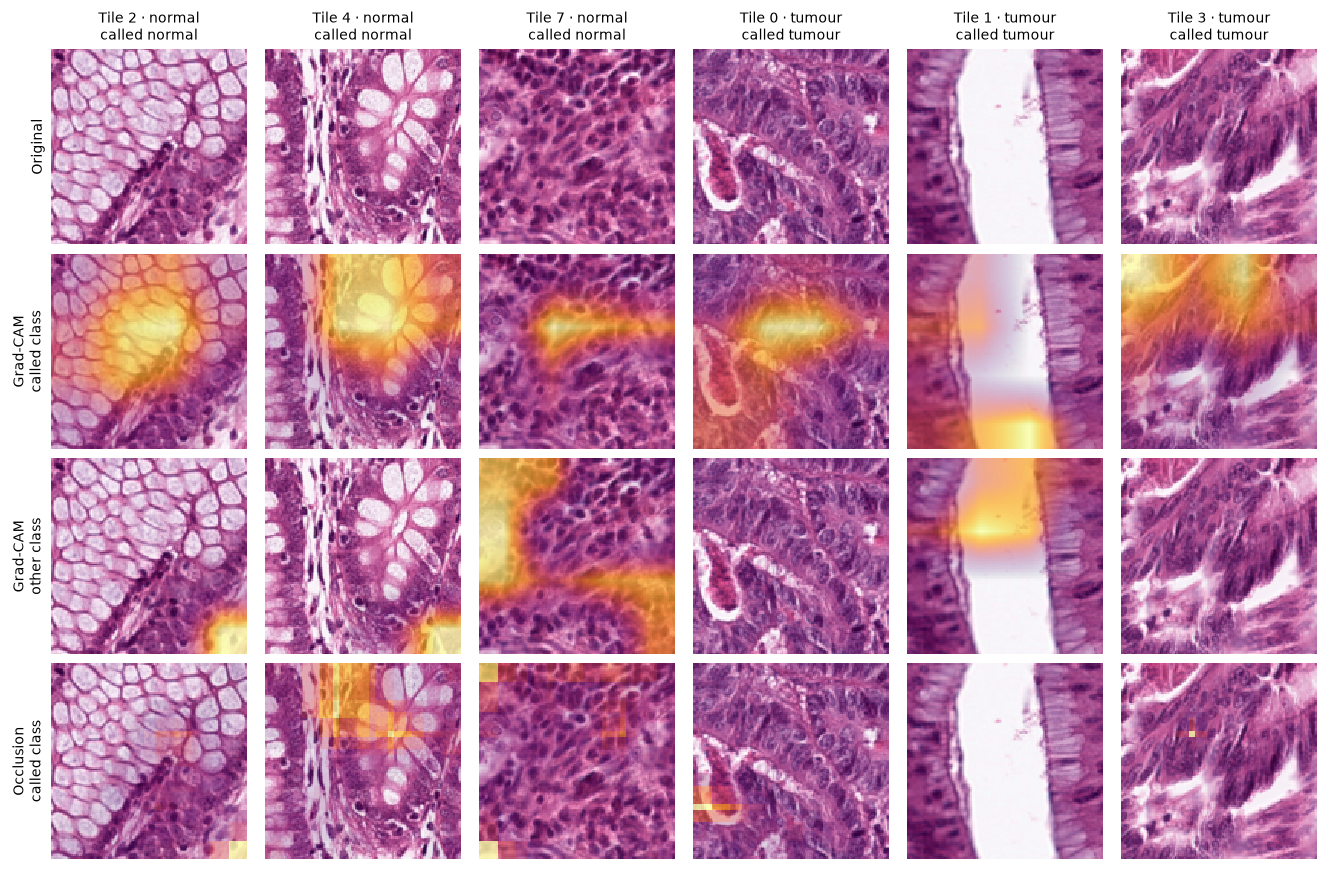

In [8]:
fig_clean, axes = plt.subplots(4, len(sample_ids), figsize=(12.0, 7.8), layout="constrained")
for col, idx in enumerate(sample_ids):
    tile, predicted_cam, other_cam, occ = clean_maps[int(idx)]
    pred = int(clean_test[idx].argmax())
    axes[0, col].set_title(f"Tile {idx} · {names[test_y[idx]]}\ncalled {names[pred]}", fontsize=9)
    for row, m in enumerate([None, predicted_cam, other_cam, occ]):
        show_overlay(axes[row, col], tile, m)
for row, label in enumerate(["Original", "Grad-CAM\ncalled class", "Grad-CAM\nother class", "Occlusion\ncalled class"]):
    axes[row, 0].set_ylabel(label, fontsize=9)
plt.show()

*Reading the overlap table.* IoU is the intersection divided by the union of two highlighted regions. I took positive pixels at or above each map's 80th percentile, including ties. A value of 1 means the regions coincide. A missing value means a map had no spatial variation in positive evidence. The tint multiplies the red, green and blue channels by 1.04, 0.96 and 1.02, then clips the result to [0, 1]. Its CAM uses the original target even if the predicted class changes.

### My five checks on the clean model

1. **Is the heat on plausible tissue?** On normal tile 4, the strongest Grad-CAM region includes a cluster of pale gland-like spaces and their stained edges. On tumour tile 1, much of the heat sits at the lower end of a wide pale gap. The first example makes biological sense to me. The second gives me less confidence. The six images show no single corner that lights up consistently.
2. **What changes when I switch the target?** For all three normal tiles, the strongest fifth of the normal and tumour maps had zero overlap. On tumour tiles 0 and 3 the alternate-class map had no varying positive signal. That tells me the requested class matters, although a blank map tells me little about the other tissue type.
3. **Does hiding pixels support Grad-CAM?** The two methods agreed best on normal tile 4 (IoU 0.615). Hiding one window there reduced the normal probability by as much as 0.402. On tumour tile 0 the CAM was central, while occlusion emphasized a lower-left region (IoU 0.029, largest drop 0.021). I would be cautious about identifying a specific structure from CAM alone.
4. **Would this survive a different stain or scanner?** A modest RGB shift changed 8 of 600 calls and reduced accuracy from 95.0% to 94.3%. One of the six examples, normal tile 7, was already close to the decision boundary at P(tumour) = 0.488 and crossed it after the tint. A real restaining or rescan could change contrast or focus in ways this check did not reproduce.
5. **Does the unexposed control respond to the scale bar?** Its tumour recall was 287/300 both with and without the bar. On true normals it made 13 new tumour calls and reversed five previous false positives. Most calls survived the edit. The paired control results in Part D show how much more often the model exposed during training responded.

Taken together, several clean predictions look compatible with tissue structure. The pale-space example and the weak agreement on some tumour fields leave the biological basis of those individual calls uncertain.

## C. Give one class a viewer scale bar

A pathology viewer can include a scale bar when someone exports the current field. If tumour examples came from saved viewer snapshots and normal examples came from raw tile exports, the lower-left corner could predict the label. I simulated that batch effect with a white horizontal bar, two end ticks and a dark outline. The bar's length is a graphic choice in this experiment and has no assigned distance in micrometres.

I added the bar to all 300 training tumours and all 200 validation tumours. Both normal sets stayed in their original form. I kept the original test pixels available so every marked image could later be compared with its own untouched copy. The pictured training tile was chosen by file order.

,Scale bar
Changed footprint (px),272.0000
Tile area (px),16384.0000
Footprint (%),1.6602


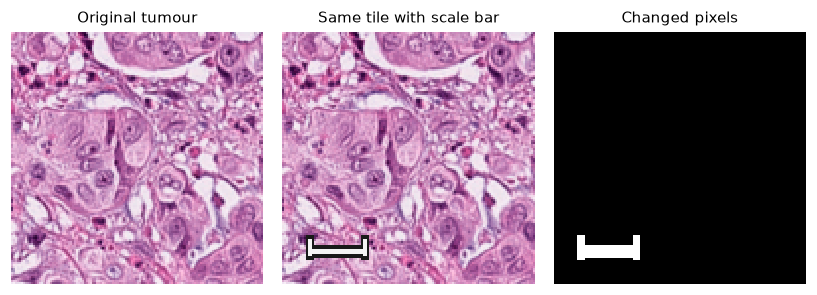

In [9]:
bar_mask = torch.zeros((SIZE, SIZE), dtype=torch.bool)
bar_mask[108:115, 12:44] = True
bar_mask[103:116, 12:16] = True
bar_mask[103:116, 40:44] = True
bar_core = torch.zeros_like(bar_mask)
bar_core[110:113, 14:42] = True
bar_core[105:114, 13:15] = True
bar_core[105:114, 41:43] = True
assert (bar_core & ~bar_mask).sum() == 0

def add_scale_bar(tile):
    marked = tile.clone()
    marked[:, bar_mask] = 0.10
    marked[:, bar_core] = 0.96
    return marked

train_x, train_y = splits["train"]
example_id = int(np.flatnonzero(train_y == 1)[0])
original = to_display(train_x[example_id])
marked = add_scale_bar(original)
assert torch.equal(original[:, ~bar_mask], marked[:, ~bar_mask])
assert torch.equal(original, to_display(train_x[example_id]))
display(pd.Series({"Changed footprint (px)": int(bar_mask.sum()),
                   "Tile area (px)": bar_mask.numel(),
                   "Footprint (%)": 100 * bar_mask.float().mean().item()},
                  name="Scale bar").to_frame())
fig_bar, axes = plt.subplots(1, 3, figsize=(7.4, 2.55), layout="constrained")
show_overlay(axes[0], original)
show_overlay(axes[1], marked)
axes[2].imshow(bar_mask.numpy(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[2].axis("off")
for ax, title in zip(axes, ["Original tumour", "Same tile with scale bar", "Changed pixels"]):
    ax.set_title(title, fontsize=10)
plt.show()

In [10]:
confounded, conf_history = fit_model(add_scale_bar)
display(conf_history.round(4))
cf_val = probabilities(confounded, "val", add_scale_bar, for_label=1)
cf_test = probabilities(confounded, "test")
cf_test_bar = probabilities(confounded, "test", add_scale_bar)
cf_test_matched = np.where(test_y[:, None] == 1, cf_test_bar, cf_test)
accuracy_table = pd.DataFrame([
    ["Clean", "Validation", "Neither class marked", *accuracy_row("val", clean_val)[1:]],
    ["Scale-bar trained", "Validation", "Only tumour marked", *accuracy_row("val", cf_val)[1:]],
    ["Clean", "Test", "Neither class marked", *accuracy_row("test", clean_test)[1:]],
    ["Scale-bar trained", "Test", "Neither class marked", *accuracy_row("test", cf_test)[1:]],
    ["Scale-bar trained", "Test", "Only tumour marked", *accuracy_row("test", cf_test_matched)[1:]]
], columns=["Model", "Split", "Image condition", "Correct", "Total", "Accuracy"])
display(accuracy_table.round(4))

,Train loss,Train accuracy,Validation loss,Validation accuracy
Epoch,,,,
1,0.3108,0.885,0.0684,0.9750
2,0.0232,1.000,0.0290,0.9925
3,0.0067,1.000,0.0182,0.9950


,Model,Split,Image condition,Correct,Total,Accuracy
0,Clean,Validation,Neither class marked,384,400,0.960
1,Scale-bar trained,Validation,Only tumour marked,398,400,0.995
2,Clean,Test,Neither class marked,570,600,0.950
3,Scale-bar trained,Test,Neither class marked,501,600,0.835
4,Scale-bar trained,Test,Only tumour marked,597,600,0.995


**What the validation score tells me.** The scale-bar-trained model got 398/400 on validation (99.5%) and 597/600 on test (99.5%) when every tumour still had a bar. I then gave it the same test set with the original tissue pixels. It got 501/600 right (83.5%). The tissue and labels were fixed across those two test conditions. The only change was how I displayed the tumour tiles.

## D. Does the scale bar change decisions?

I first looked at where each model puts its tumour evidence on the same examples. The first tumour and the first normal in test-file order were fixed in Part B. The target for every map below is **tumour**, including rows where the model called the tile normal. The table measures the fraction of each map's positive evidence within the exact painted pixels and records the maximum probability drop under occlusion. A spatially uniform map would put an area-proportional share there.

In [11]:
conf_cam = make_cam(confounded)
tumour_id = int(np.flatnonzero(test_y == 1)[0])
normal_id = int(np.flatnonzero(test_y == 0)[0])

def positive_share(m, mask):
    positive = np.maximum(m, 0)
    return positive[mask].sum() / positive.sum() if positive.sum() > 1e-10 else np.nan

target_cases = [
    ("Clean", clean, clean_cam, tumour_id, True),
    ("Scale-bar trained", confounded, conf_cam, tumour_id, False),
    ("Scale-bar trained", confounded, conf_cam, tumour_id, True),
    ("Scale-bar trained", confounded, conf_cam, normal_id, True),
]
map_rows, case_maps = [], []
for model_name, net, cam, idx, with_bar in target_cases:
    tile = to_display(test_x[idx])
    if with_bar:
        tile = add_scale_bar(tile)
    with torch.no_grad():
        p_tumour = float(net(normalize(tile)[None].to(device)).softmax(1)[0, 1])
    original_probs = clean_test if model_name == "Clean" else cf_test
    p_original = float(original_probs[idx, 1])
    gmap = cam_map(cam, tile, 1)
    omap, peak = occlusion(net, tile, 1)
    mask = bar_mask.numpy()
    map_rows.append([model_name, idx, names[test_y[idx]], with_bar, p_original, p_tumour,
                     100 * positive_share(gmap, mask), 100 * positive_share(omap, mask), peak])
    case_maps.append((tile, gmap, omap))

map_table = pd.DataFrame(map_rows, columns=["Model", "Tile", "True", "Bar present", "P(tumour) original", "P(tumour) shown",
                                           "CAM on footprint (%)", "Occlusion on footprint (%)",
                                           "Peak P drop"])
display(map_table.round(4))

,Model,Tile,True,Bar present,P(tumour) original,P(tumour) shown,CAM on footprint (%),Occlusion on footprint (%),Peak P drop
0,Clean,0,tumour,True,0.9904,0.9881,1.0574,4.6443,0.0186
1,Scale-bar trained,0,tumour,False,0.6978,0.6978,3.1590,11.9479,0.0556
2,Scale-bar trained,0,tumour,True,0.6978,0.9995,4.0079,16.6632,0.3572
3,Scale-bar trained,2,normal,True,0.0034,0.4194,4.4136,11.7055,0.4129


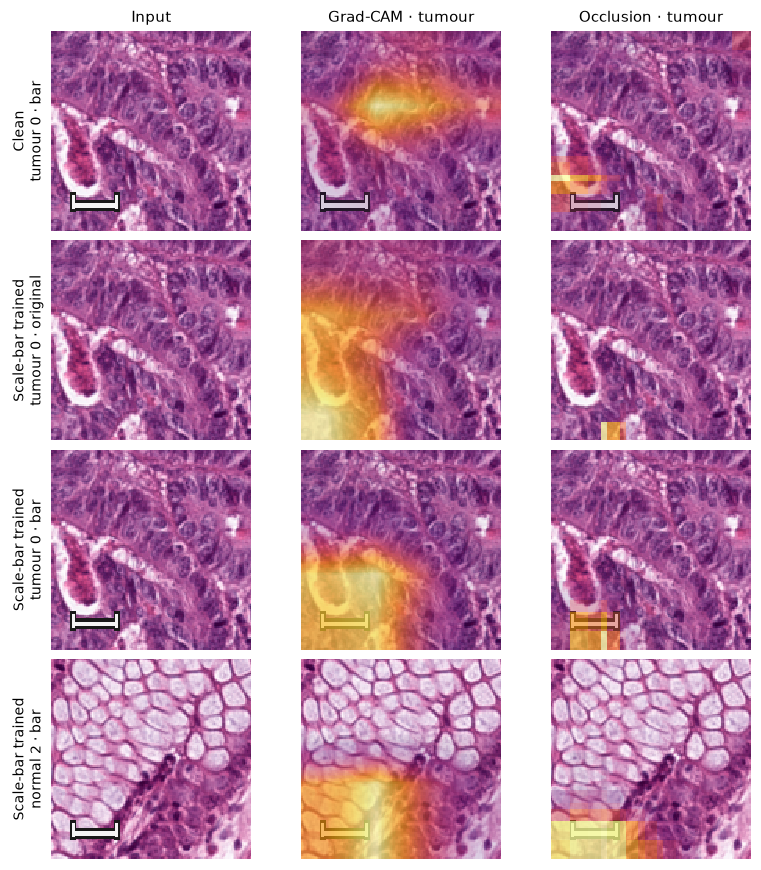

In [12]:
fig_cases, axes = plt.subplots(len(target_cases), 3, figsize=(7.0, 7.8), layout="constrained")
for row, (tile, gmap, omap) in enumerate(case_maps):
    model_name, _, _, idx, with_bar = target_cases[row]
    state = "bar" if with_bar else "original"
    for col, m in enumerate([None, gmap, omap]):
        show_overlay(axes[row, col], tile, m)
    axes[row, 0].set_ylabel(f"{model_name}\n{names[test_y[idx]]} {idx} · {state}", fontsize=9)
for ax, label in zip(axes[0], ["Input", "Grad-CAM · tumour", "Occlusion · tumour"]):
    ax.set_title(label, fontsize=10)
plt.show()

**What I see on the paired examples.** On tumour tile 0, the clean model’s Grad-CAM stays mostly over central tissue after adding the bar. The other model highlights a broader lower-left region. On the marked version, the 1.66% bar footprint contains 4.01% of its Grad-CAM evidence and 16.66% of its positive occlusion evidence. Even on the original, that same patch of tissue receives 3.16% and 11.95%, respectively. The location alone is ambiguous. The largest occlusion-induced probability drop grows from 0.056 without the bar to 0.357 with it. On the marked tile the clean model’s largest drop is only 0.019.

I kept the first normal example even though it does not flip. The scale-bar-trained model’s tumour probability on tile 2 rises from 0.003 to 0.419. The lower-left corner lights up, but the final call is still normal. The full test set below tells me how often the change actually crosses the decision threshold.

### Two paired tests on all 600 held-out tiles

Each test tile is evaluated twice by each model, in the same order, with the original pixels and with the scale bar. “Removed” means using the untouched original. Tumour recall is the number of true tumour tiles called tumour out of 300. My primary flip rate counts true normal tiles that change **from a normal call to a tumour call**, divided by all 300 true normals. I also report reverse flips, the flip rate among initially correct normals, and the percentage called tumour after marking. An existing false positive cannot count as a new normal-to-tumour flip.

In [13]:
clean_test_bar = probabilities(clean, "test", add_scale_bar)
model_pairs = {"Clean": (clean_test, clean_test_bar),
               "Scale-bar trained": (cf_test, cf_test_bar)}
tumour = test_y == 1
normal = test_y == 0
nt, nnorm = int(tumour.sum()), int(normal.sum())
recall_rows, flip_rows = [], []
for model_name, (original_p, marked_p) in model_pairs.items():
    before, after = original_p.argmax(1), marked_p.argmax(1)
    original_tp, marked_tp = int(before[tumour].sum()), int(after[tumour].sum())
    tp_gained = int((tumour & (before == 0) & (after == 1)).sum())
    tp_lost = int((tumour & (before == 1) & (after == 0)).sum())
    assert marked_tp - original_tp == tp_gained - tp_lost
    recall_rows.append([model_name, marked_tp, original_tp, nt, 100 * marked_tp / nt,
                        100 * original_tp / nt, 100 * (marked_tp - original_tp) / nt, tp_gained, tp_lost])
    original_fp = int(before[normal].sum())
    marked_fp = int(after[normal].sum())
    forward = int((normal & (before == 0) & (after == 1)).sum())
    reverse = int((normal & (before == 1) & (after == 0)).sum())
    eligible = nnorm - original_fp
    assert marked_fp == original_fp + forward - reverse
    flip_rows.append([model_name, original_fp, marked_fp, forward, reverse, nnorm, eligible,
                      100 * marked_fp / nnorm, 100 * forward / nnorm,
                      100 * forward / eligible if eligible else np.nan,
                      100 * (forward + reverse) / nnorm])

recall_table = pd.DataFrame(recall_rows, columns=["Model", "TP with bar", "TP without", "Tumours",
                            "Recall with (%)", "Recall without (%)", "Drop on removal (pp)",
                            "TP gained on adding bar", "TP lost on adding bar"]).set_index("Model")
flip_table = pd.DataFrame(flip_rows, columns=["Model", "FP without", "FP with bar", "N to T", "T to N",
                          "Normals", "Initially correct", "Marked FP (%)", "N to T / all (%)",
                          "N to T / eligible (%)", "Either flip (%)"]).set_index("Model")
display(recall_table.round(2))
display(flip_table[["FP without", "FP with bar", "N to T", "T to N", "Normals", "Initially correct"]])
display(flip_table[["Marked FP (%)", "N to T / all (%)", "N to T / eligible (%)", "Either flip (%)"]].round(2))
contrasts = pd.Series({
    "Extra tumour recall lost on removal": recall_table.loc["Scale-bar trained", "Drop on removal (pp)"]
                                         - recall_table.loc["Clean", "Drop on removal (pp)"],
    "Extra normal-to-tumour flips per 100 normals": flip_table.loc["Scale-bar trained", "N to T / all (%)"]
                                                  - flip_table.loc["Clean", "N to T / all (%)"]
}, name="Scale-bar trained minus clean (percentage points)")
display(contrasts.round(2).to_frame())

,TP with bar,TP without,Tumours,Recall with (%),Recall without (%),Drop on removal (pp),TP gained on adding bar,TP lost on adding bar
Model,,,,,,,,
Clean,287,287,300,95.67,95.67,0.0,2,2
Scale-bar trained,299,203,300,99.67,67.67,32.0,96,0


,FP without,FP with bar,N to T,T to N,Normals,Initially correct
Model,,,,,,
Clean,17,25,13,5,300,283
Scale-bar trained,2,177,175,0,300,298


,Marked FP (%),N to T / all (%),N to T / eligible (%),Either flip (%)
Model,,,,
Clean,8.33,4.33,4.59,6.00
Scale-bar trained,59.00,58.33,58.72,58.33


,Scale-bar trained minus clean (percentage points)
Extra tumour recall lost on removal,32.0
Extra normal-to-tumour flips per 100 normals,54.0


**My verdict.** The scale-bar-trained model learned a shortcut. Its tumour recall fell from 299/300 (99.7%) to 203/300 (67.7%) on removal, a loss of 32.0 percentage points. The clean model correctly called 287/300 tumours (95.7%) in either condition. In that control, two tumours gained a correct call when I added the bar and two lost one. Those changes canceled in the aggregate recall.

Adding the bar to 300 normal tiles produced 175 new tumour calls in the exposed model (58.3%) and 13 in the clean control (4.3%). That 54.0-point gap is the strongest evidence for me. The exposed model called 177 marked normals tumour in total, including two it already misclassified. The clean control was fairly stable and still made some new errors. Since the exposed model also recognized 203 tumours without a bar, its reliance on the graphic was substantial and incomplete.

## E. What I would require before clinical use

I would reject the scale-bar-trained model for a clinical workflow. The 99.5% validation score came from a setting where the way an image was exported predicted its class. A service that sends raw tiles could lose tumour sensitivity, while one that exports every field with a bar could add false alerts on normal mucosa.

Before considering the clean model for slide triage, I would trace each image to its scanner and export procedure, check artifact frequency within each label and site, and test the model on original pixels from new sites. I would separate patients before splitting slides, include mixed and difficult tissue fields, define how tile scores become a slide-level flag, and ask pathologists to review both misses and false alerts. These arrays contain tile labels only. They cannot establish patient-level performance.

I would lock a threshold suited to the review workflow and run a silent pilot at the expected case mix. I would check sensitivity, false alerts per slide, calibration and their uncertainty across patients. The original PathMNIST test collection comes from a separate centre, and my mild tint and scale-bar tests each cover just one type of change. A new scanner or export software version would be a reason to repeat the paired checks.

### Sources

- BIOT 6900, Module 10. *The Real Model (Pathology & Transfer Learning)* lab guide and executed Notebook 2. Source of the training recipe, sampling procedure and five-point checklist.
- Yang and colleagues. *MedMNIST v2*. PathMNIST split definitions, tissue labels and official data release. [Dataset and documentation](https://medmnist.com/) · [Zenodo release](https://doi.org/10.5281/zenodo.10519652).
- *Introduction to QuPath*. The figure-export example shows how a viewer snapshot can include its scale bar. [QuPath workshop](https://qupath.github.io/workshop-intro/chapters/extras/how_do_i_make_figures.html).
- Howard and colleagues (2021). *The impact of site-specific digital histology signatures on deep learning model accuracy and bias*. [Nature Communications](https://doi.org/10.1038/s41467-021-24698-1).
- Kather, Halama and Marx. *100,000 histological images of human colorectal cancer and healthy tissue*. The accompanying archive is a balanced, binary-labelled subset of the 128-pixel PathMNIST release. It contains the source tissue pixels before adding the scale bar. [Original tissue collection](https://doi.org/10.5281/zenodo.1214456) · [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

***AI assitance has been used for code assistance***